# What is GFTM getting wrong on R4, and where else? (Fusion_PhD-38e9.28)

Advisory agent analysis. Every number comes from pyro `pyroscan.nc` / `cube.nc` objects on Pitagora; nothing is read
from a CSV. Background (Fusion_PhD `results/beta_stabilisation_f05/README.md`, 38e9.9): above GS2 β ≈ 0.07 GFTM finds a
compact, even-parity, low-ω KBM on R4 that GS2 does not have; it is B∥-driven, rises with WIDTH and is not converged
in NXGRID.

1. **Numerical settings** on R4 (3 ky × 19 β): max basis (NBASIS 59 / NXGRID 65), FILTER, NMODES, IBRANCH,
   USE_MHD_RULE, velocity resolution (NU/NE). Leaves `GFTM/Runs/scan_beta_f05_diag/R4/*` (GyroRun).
2. **Extents** of every GFTM mode (FILTER 0, NMODES 8) against GS2's mode.
3. **Mode selection and frequency**: the whole unstable GFTM spectrum against GS2, and whether a selection rule finds
   the GS2-like mode.
4. **Other bad cases**: the KBM hypercubes, the β scans and the S1_3 q/ŝ scans, and what the badly-wrong cases share.

GS2 is initial-value: one mode per run, so there is no GS2 subdominant mode to compare against.

In [1]:
from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter
from scipy.integrate import trapezoid
from dotenv import load_dotenv
import pyrokinetics
from pyrokinetics import PyroScan
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.diagnostics import Diagnostics
from pyrokinetics.diagnostics.extent import Extent
from general_analysis import mode_classification as mc

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "gftm_r4_diagnosis"
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
run_template = "Runs"
plot_dir = ROOT / "Plots" / analysis_name
plot_dir.mkdir(parents=True, exist_ok=True)

case = "R4"
ky_targets = [0.1, 0.2, 0.3]                  # snapped to GS2's grid
beta_high, beta_low = 0.07, 0.05              # GS2 beta numbers: high-beta cells >= 0.07, low-beta control <= 0.05
tol_unconverged = 0.1                         # GS2 growth_rate_tolerance at or above this: unconverged (38e9.9)
fraction = 0.95                               # pyro Extent fraction
gs2_leaf = ("GS2", "scan_beta", "parameter_scan_GS2")
# GFTM leaves on R4: label -> (project, leaf, WIDTH). "base" = FILTER 0.5, NMODES 2, NBASIS 12, NXGRID 32, NU 7, NE 3.
leaves = {
    "base w0.3": ("scan_beta_f05_conv", "width_0p3", 0.3),
    "base w0.8": ("scan_beta_f05", "w0p8", 0.8),
    "base w1.74": ("scan_beta", "parameter_scan_gftm_default", 1.74),   # beta labelled with GS2's numbers (f = 1)
    "nobpar w0.8": ("scan_beta_f05_conv", "nobpar_w0p8", 0.8),
    **{f"maxb w{w:g}": ("scan_beta_f05_diag", f"maxb_w{w:g}".replace(".", "p"), w) for w in (0.3, 0.8, 1.74)},
    **{f"spec w{w:g}": ("scan_beta_f05_diag", f"spec_w{w:g}".replace(".", "p"), w) for w in (0.3, 0.8, 1.74)},
    "spec maxb w0.8": ("scan_beta_f05_diag", "spec_maxb_w0p8", 0.8),
    "ibranch0 w0.8": ("scan_beta_f05_diag", "ibr0_w0p8", 0.8),
    "filter0.7 w0.8": ("scan_beta_f05_diag", "filt0p7_w0p8", 0.8),
    "filter0.9 w0.8": ("scan_beta_f05_diag", "filt0p9_w0p8", 0.8),
    "mhd w0.8": ("scan_beta_f05_diag", "mhd_w0p8", 0.8),
    "mhd nobpar w0.8": ("scan_beta_f05_diag", "mhd_nobpar_w0p8", 0.8),
    **{f"vel w{w:g}": ("scan_beta_f05_diag", f"vel_w{w:g}".replace(".", "p"), w) for w in (0.3, 0.8)},
}
fs_title, fs_label, fs_tick, fs_legend = 16, 16, 14, 12
field_label = {"phi": r"$\phi$", "apar": r"$A_\parallel$", "bpar": r"$B_\parallel$"}

pyrokinetics 0.9.2.dev149+gf119e687


## Load R4: GS2 and every GFTM leaf
Each leaf is a PyroScan with its `pyroscan.nc`; pyro `Extent` (95%) is added per field and mode. GFTM's ky grid is
selected onto GS2's three ky (asserted), and β is matched by index (GFTM stores pyro β = GS2 β × f, asserted constant).

In [2]:
def v(da):
    return np.asarray(getattr(da.data, "magnitude", da.data))


def load_leaf(code, project, leaf):
    d = data_root / code / run_template / project / case / leaf
    s = PyroScan(pyroscan_json=d / "pyroscan.json", load_base_pyro=True)
    s.load_gk_output(netcdf_file=d / "pyroscan.nc")
    Extent(s.gk_output, fraction=fraction)
    out = s.gk_output.data
    for dim in ("bpar", "kx"):   # nobpar leaves scan numerics.bpar = [False]; GFTM writes a length-1 kx
        out = out.squeeze(dim, drop=True) if dim in out.dims else out
    return out


gs2_all = load_leaf(*gs2_leaf)
iky = [int(np.abs(v(gs2_all.ky) - k).argmin()) for k in ky_targets]
G = gs2_all.isel(ky=iky).transpose("ky", "beta", ...)
beta = v(G.beta)
ky = v(G.ky)
tol = v(G.growth_rate_tolerance)
unconv = tol >= tol_unconverged
hi, lo = beta >= beta_high, beta <= beta_low
g_gs2, w_gs2 = v(G.growth_rate), v(G.mode_frequency)

R = {}
for lab, (project, leaf, _) in leaves.items():
    d = load_leaf("GFTM", project, leaf)
    d = d.sel(ky=ky, method="nearest").transpose("ky", "beta", "mode", ...)
    assert np.allclose(v(d.ky), ky, atol=1e-3) and d.beta.size == beta.size, lab
    f = v(d.beta) / beta
    assert np.allclose(f, f[0], rtol=1e-3), (lab, "beta is not GS2 beta x constant")
    R[lab] = d
print("ky", ky.round(3), "| GS2 beta", beta.round(2))
print("modes per leaf:", {lab: int(d.mode.size) for lab, d in R.items()})
print("GS2 unconverged (tol >= 0.1) at beta >= 0.07:", int(unconv[:, hi].sum()), "of", int(hi.sum() * len(ky)))

ky [0.112 0.2   0.3  ] | GS2 beta [0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13 0.14
 0.15 0.16 0.17 0.18 0.19]
modes per leaf: {'base w0.3': 2, 'base w0.8': 2, 'base w1.74': 2, 'nobpar w0.8': 2, 'maxb w0.3': 2, 'maxb w0.8': 2, 'maxb w1.74': 2, 'spec w0.3': 8, 'spec w0.8': 8, 'spec w1.74': 8, 'spec maxb w0.8': 8, 'ibranch0 w0.8': 2, 'filter0.7 w0.8': 2, 'filter0.9 w0.8': 2, 'mhd w0.8': 2, 'mhd nobpar w0.8': 2, 'vel w0.3': 2, 'vel w0.8': 2}
GS2 unconverged (tol >= 0.1) at beta >= 0.07: 31 of 39


## (4) Other databases: where else is GFTM badly wrong, and what do those cases share?
GFTM at WIDTH 0.4 and 0.8, dominant mode, against GS2 on every database with both:

| database | GS2 | GFTM (both FILTER 0.5 unless noted) |
|---|---|---|
| SPR-045, M1 (KBM hypercubes) | `LATIN_HYPERCUBE/<db>/kbm_8d`, γ from `pyro_cube_avg` | `wo_f05_w0p4000`, `wo_f05_w0p8000` (NBASIS 22 / NXGRID 28) |
| R4 hypercube | `LATIN_HYPERCUBE/R4/kbm_8d/pyro_cube` (no averaged cube) | `wo_w0p4000`, `wo_w0p8000` (**FILTER 0**; no FILTER 0.5 arm exists) |
| R3, R4, M1_A1_NE (β scans) | `scan_beta/<case>/parameter_scan_GS2` | `scan_beta_f05/<case>/w0p4`, `w0p8` |
| S1_3 q, ŝ scans | `scan_{q,shat}/S1_3/parameter_scan_GS2` | `scan_{q,shat}_f05/S1_3/w0p4`, `w0p8` |

**Bad** = `over` (GS2 γ > 0.01 and γ_GFTM > 3 γ_GS2) or `spurious` (GS2 γ ≤ 0.01 and γ_GFTM > 0.1).
**Good** = GS2 γ > 0.01 and γ_GFTM within ×1.5. Features per case: ky, β, α = q²(R/a)|β′| (β′ in pyro normalisation,
from each sample's own Pyro via `sample_pyro`), q, ŝ, GS2 class (cube classifier) and tolerance, GFTM's dominant ω, T,
φ extent, and ky·(|B∥|/|φ|)_GFTM (the ky-corrected B∥ share of `gftm_bpar_ratio`).

In [11]:
over_factor, good_factor, g_floor, spur_gamma = 3.0, 1.5, 0.01, 0.1
widths = (0.4, 0.8)
dbs = {   # name -> (kind, GS2 path, GS2 gamma cube or scan parameter, {WIDTH: GFTM path})
    "SPR-045": ("cube", "GS2/Runs/LATIN_HYPERCUBE/SPR-045/kbm_8d", "pyro_cube_avg",
                {w: f"GFTM/Runs/LATIN_HYPERCUBE/SPR-045/kbm_8d/wo_f05_w0p{int(w * 10)}000" for w in widths}),
    "M1": ("cube", "GS2/Runs/LATIN_HYPERCUBE/M1/kbm_8d", "pyro_cube_avg",
           {w: f"GFTM/Runs/LATIN_HYPERCUBE/M1/kbm_8d/wo_f05_w0p{int(w * 10)}000" for w in widths}),
    "R4 cube": ("cube", "GS2/Runs/LATIN_HYPERCUBE/R4/kbm_8d", "pyro_cube",
                {w: f"GFTM/Runs/LATIN_HYPERCUBE/R4/kbm_8d/wo_w0p{int(w * 10)}000" for w in widths}),
    **{c: ("scan", f"GS2/Runs/scan_beta/{c}/parameter_scan_GS2", "beta",
           {w: f"GFTM/Runs/scan_beta_f05/{c}/w0p{int(w * 10)}" for w in widths}) for c in ("R3", "R4", "M1_A1_NE")},
    **{f"S1_3 {p}": ("scan", f"GS2/Runs/scan_{p}/S1_3/parameter_scan_GS2", p,
                     {w: f"GFTM/Runs/scan_{p}_f05/S1_3/w0p{int(w * 10)}" for w in widths}) for p in ("q", "shat")},
}


def gk(path):
    "pyro gk output of a GFTM leaf (cube.nc or pyroscan.nc), with pyro Extent, dequantified"
    path = Path(path)
    nc = path / "pyro_cube" / "cube.nc" if (path / "pyro_cube" / "cube.nc").exists() else path / "pyroscan.nc"
    o = PyroScanGKOutput.from_netcdf(nc)
    Extent(o, fraction=fraction)
    out = o.data.pint.dequantify()
    return out.squeeze("kx", drop=True) if "kx" in out.dims else out


def peak_ratio(ef):
    "peak|B_par| / peak|phi| over theta of a (..., field, theta) eigenfunction array"
    a = np.abs(np.nan_to_num(ef))
    return a[..., 2, :].max(-1) / a[..., 0, :].max(-1)


def sample_features(scan, n):
    "ky, beta, q, shat and alpha of every sample, from the sample's own Pyro (scanned values and derived beta_prime applied)"
    rows = []
    for i in range(n):
        p = scan.sample_pyro(i)
        lg = p.local_geometry
        rows.append({"ky": float(p.numerics.ky.to(p.norms.pyrokinetics).m), "beta": float(p.numerics.beta.to(p.norms.pyrokinetics).m),
                     "q": float(lg.q.m), "shat": float(lg.shat.m),
                     "alpha": float(lg.q.m ** 2 * lg.Rmaj.m * abs(lg.beta_prime.to(p.norms.pyrokinetics).m))})
    return pd.DataFrame(rows)


def gs2_scan(kind, gs2_path):
    "(scan, final-time sample dataset, unstacked grid or None) of a GS2 cube or gridded scan"
    if kind == "cube":
        return *mc.load_gs2_cube(data_root / gs2_path, "pyro_cube"), None
    leaf = data_root / gs2_path
    scan = mc.attach_legacy_funcs(PyroScan(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True,
                                           base_directory=leaf, file_name="gs2.in"))
    grid = PyroScanGKOutput.from_netcdf(leaf / "pyroscan.nc").data
    return scan, mc.as_samples(scan, grid), grid


tables = []
for db, (kind, gs2_path, gref, gftm_paths) in dbs.items():
    scan, ds, grid = gs2_scan(kind, gs2_path)
    gs = ds if grid is not None else PyroScanGKOutput.from_netcdf(data_root / gs2_path / gref / "cube.nc").data
    names = ds.sample_name.values.astype(str)
    assert (gs.sample_name.values.astype(str) == names).all()
    n = len(names)
    label = np.asarray(mc.classify(mc.indicators(scan, ds)))
    base = pd.concat([pd.DataFrame({"db": db, "sample": names, "g_gs2": v(gs.growth_rate).ravel(),
                                    "tol_gs2": v(ds.growth_rate_tolerance).ravel(), "gs2_class": label}),
                      sample_features(scan, n)], axis=1)
    for wd, gp in gftm_paths.items():
        d = gk(data_root / gp)
        if grid is not None:   # GFTM's grid may hold extra ky: select GS2's, then stack in GS2's sample order
            d = mc.as_samples(scan, d.sel(ky=v(grid.ky), method="nearest"))
            assert np.allclose(v(d.ky), base.ky, rtol=1e-3), (db, wd, "ky differs from GS2")
        d = d.transpose("sample", "mode", ...)
        m = xr.DataArray(np.nan_to_num(v(d.growth_rate), nan=-np.inf).argmax(-1), dims="sample")
        dd = d.isel(mode=m)
        if "tearing_parameter" in d:
            T = v(dd.tearing_parameter)
        else:   # hypercube GFTM cubes store no T: FieldLine on each sample's own geometry, in the cube's own order
            T = v(mc.tearing_parity(mc.load_gftm_cube(data_root / gp)[0], dd)["T"]).ravel()
        dd = dd.assign(T=("sample", T))
        if grid is None:
            idx = pd.Index(dd.sample_name.values.astype(str)).get_indexer(names)
            assert (idx >= 0).all(), (db, wd, "GS2 samples missing from GFTM")
            dd = dd.isel(sample=idx)
        gd = v(dd.growth_rate)
        tables.append(base.assign(width=wd, g_gftm=np.where(np.isfinite(gd) & (gd > 0), gd, 0.0), w_gftm=v(dd.mode_frequency),
                                  T_gftm=v(dd["T"]), ext_gftm=v(dd.extent.sel(field="phi")),
                                  kyr_gftm=base.ky.values * peak_ratio(v(dd.eigenfunctions.transpose("sample", "field", "theta")))))
    print(db, "samples", n, "| GS2 gamma > 0.01:", int((base.g_gs2 > g_floor).sum()), "| classes", pd.Series(label).value_counts().to_dict())

D = pd.concat(tables, ignore_index=True)
ratio = D.g_gftm / D.g_gs2
D["cls"] = np.select([(D.g_gs2 > g_floor) & (ratio > over_factor), (D.g_gs2 <= g_floor) & (D.g_gftm > spur_gamma),
                      (D.g_gs2 > g_floor) & (ratio < good_factor) & (ratio > 1 / good_factor)],
                     ["over", "spurious", "good"], "other")
D["bad"] = D.cls.isin(["over", "spurious"])
print(D.groupby(["width", "db"], sort=False).cls.value_counts().unstack(fill_value=0).to_string())

SPR-045 samples 300 | GS2 gamma > 0.01: 164 | classes {'mixed': 175, 'KBM': 125}


M1 samples 300 | GS2 gamma > 0.01: 232 | classes {'KBM': 167, 'mixed': 113, 'MTM': 20}


R4 cube samples 500 | GS2 gamma > 0.01: 484 | classes {'KBM': 280, 'mixed': 220}


R3 samples 798 | GS2 gamma > 0.01: 668 | classes {'mixed': 341, 'MTM': 274, 'KBM': 183}


R4 samples 798 | GS2 gamma > 0.01: 283 | classes {'mixed': 404, 'MTM': 222, 'KBM': 172}


M1_A1_NE samples 760 | GS2 gamma > 0.01: 355 | classes {'mixed': 377, 'KBM': 361, 'MTM': 22}


S1_3 q samples 110 | GS2 gamma > 0.01: 68 | classes {'mixed': 46, 'KBM': 41, 'MTM': 23}


S1_3 shat samples 110 | GS2 gamma > 0.01: 90 | classes {'KBM': 46, 'MTM': 39, 'mixed': 25}
cls              other  good  over  spurious
width db                                    
0.4   SPR-045      177   120     3         0
      M1           102   162    21        15
      R4 cube      151   319    24         6
      R3           335   385    78         0
      R4           330   167    43       258
      M1_A1_NE     495   127    69        69
      S1_3 q        68    36     6         0
      S1_3 shat     40    64     6         0
0.8   SPR-045      154   119    12        15
      M1            78   157    38        27
      R4 cube      169   320    10         1
      R3           332   401    59         6
      R4           214   134   105       345
      M1_A1_NE     471   142    61        86
      S1_3 q        63    36     7         4
      S1_3 shat     44    47    15         4


### The common thread
Databases span different parameter ranges, so each feature is turned into its **percentile within its own database
and WIDTH** before pooling. A feature unrelated to badness puts the bad cases at a median percentile of 0.5. Shown for
all bad cases and for `over` and `spurious` separately; per-database medians are printed below.

median within-database percentile of each feature (0.5 = no signal); n: {(0.4, 'bad'): 598, (0.4, 'over'): 250, (0.4, 'spurious'): 348, (0.4, 'good'): 1380, (0.8, 'bad'): 795, (0.8, 'over'): 307, (0.8, 'spurious'): 488, (0.8, 'good'): 1356}
           0.4                        0.8                     
           bad  over spurious  good   bad  over spurious  good
ky        0.71  0.69     0.73  0.42  0.56  0.56     0.56  0.41
beta      0.55  0.43     0.66  0.42  0.61  0.55     0.66  0.42
alpha     0.55  0.45     0.66  0.43  0.61  0.55     0.66  0.44
q         0.62  0.62     0.65  0.54  0.54  0.55     0.52  0.55
shat      0.75  0.76     0.72  0.45  0.56  0.50     0.59  0.47
tol_gs2   0.65  0.58     0.69  0.29  0.62  0.53     0.66  0.27
w_gftm    0.29  0.44     0.25  0.49  0.50  0.50     0.31  0.52
T_gftm    0.72  0.68     0.74  0.36  0.61  0.60     0.63  0.44
ext_gftm  0.73  0.69     0.75  0.43  0.50  0.46     0.59  0.43
kyr_gftm  0.31  0.34     0.28  0.52  0.40  0.35     0.43  0.53


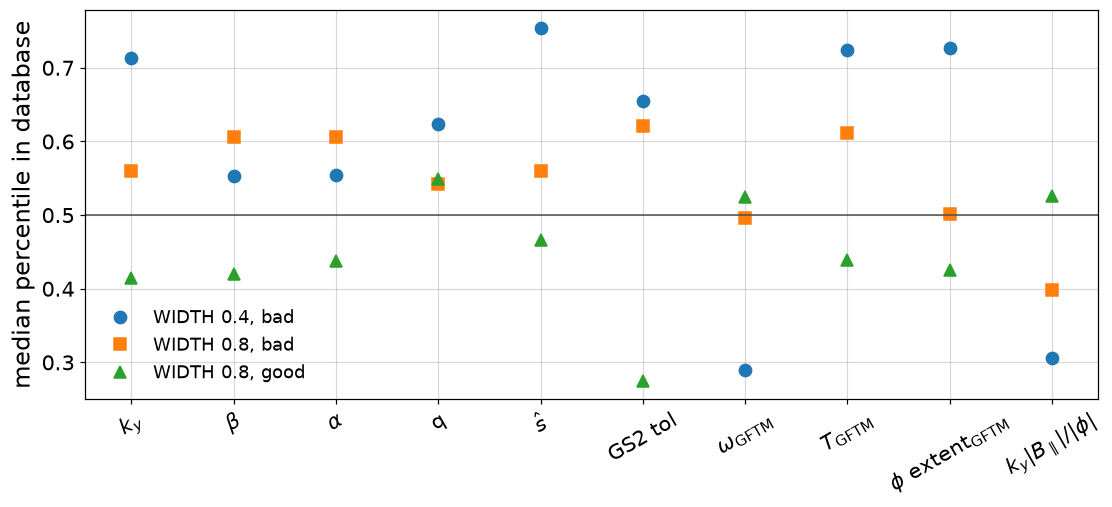

family           ion, ky<0.5  electron, ky>=0.5  ion, ky>=0.5  electron, ky<0.5
width db                                                                       
0.4   SPR-045              3                  0             0                 0
      M1                  11                 11            11                 3
      R4 cube             19                  5             1                 5
      R3                   0                 68             9                 1
      R4                  92                190            16                 3
      M1_A1_NE            41                  0            96                 1
      S1_3 q               0                  0             6                 0
      S1_3 shat            0                  0             6                 0
0.8   SPR-045             27                  0             0                 0
      M1                  15                 19            10                21
      R4 cube              2            

gs2_class        mixed  KBM  MTM
width db                        
0.4   SPR-045        1    2    0
      M1            23   12    1
      R4 cube       16   14    0
      R3            70    1    7
      R4           182   14  105
      M1_A1_NE      69   66    3
      S1_3 q         1    5    0
      S1_3 shat      0    4    2
0.8   SPR-045       17   10    0
      M1            35   26    4
      R4 cube        1   10    0
      R3            53    9    3
      R4           241   42  167
      M1_A1_NE      80   62    5
      S1_3 q         2    6    3
      S1_3 shat      4    4   11


In [12]:
features = ["ky", "beta", "alpha", "q", "shat", "tol_gs2", "w_gftm", "T_gftm", "ext_gftm", "kyr_gftm"]
feature_label = {"ky": r"$k_y$", "beta": r"$\beta$", "alpha": r"$\alpha$", "q": "q", "shat": r"$\hat{s}$",
                 "tol_gs2": "GS2 tol", "w_gftm": r"$\omega_{\rm GFTM}$", "T_gftm": r"$T_{\rm GFTM}$",
                 "ext_gftm": r"$\phi$ extent$_{\rm GFTM}$", "kyr_gftm": r"$k_y|B_\parallel|/|\phi|$"}
P = D.copy()
for f in features:   # NaN where the feature is constant within the database (q and shat on the beta scans)
    P[f] = D.groupby(["db", "width"])[f].transform(lambda x: x.rank(pct=True) if x.nunique() > 1 else np.nan)
thread = pd.DataFrame({(wd, c): P[(P.width == wd) & (P.cls.isin(["over", "spurious"]) if c == "bad" else P.cls == c)][features].median()
                       for wd in widths for c in ("bad", "over", "spurious", "good")})
print("median within-database percentile of each feature (0.5 = no signal); n:",
      {(wd, c): int(((P.width == wd) & (P.cls.isin(["over", "spurious"]) if c == "bad" else P.cls == c)).sum())
       for wd in widths for c in ("bad", "over", "spurious", "good")})
print(thread.round(2).to_string())

fig_thread, ax = plt.subplots(figsize=(10, 4.5))
for n, (wd, c) in enumerate([(0.4, "bad"), (0.8, "bad"), (0.8, "good")]):
    ax.plot(range(len(features)), thread[(wd, c)], ls="", marker="os^"[n], ms=8, color=f"C{n}", label=f"WIDTH {wd}, {c}")
ax.axhline(0.5, color="0.3", lw=1, marker="")
ax.set_xticks(range(len(features)))
ax.set_xticklabels([feature_label[f] for f in features], rotation=30)
ax.set_ylabel("median percentile in database", fontsize=fs_label)
ax.tick_params(labelsize=fs_tick)
ax.legend(fontsize=fs_legend)
fig_thread.savefig(plot_dir / "gftm_high_error_case_parameter_percentile_per_parameter.png", dpi=150, bbox_inches="tight")
plt.show()

with pd.option_context("display.width", 250):
    # two candidate families: GFTM's dominant mode in the ion (omega > 0) or electron direction, at low or high ky
    P["family"] = np.where(mc.ION_DIRECTION * D.w_gftm > 0, "ion", "electron") + np.where(D.ky >= 0.5, ", ky>=0.5", ", ky<0.5")
    print(P[P.bad].groupby(["width", "db"], sort=False).family.value_counts().unstack(fill_value=0).to_string())
    print(P[P.bad].groupby(["width", "family"]).agg(n=("ky", "size"), alpha_pct=("alpha", "median"), beta_pct=("beta", "median"),
                                                    g_gs2=("g_gs2", "median"), g_gftm=("g_gftm", "median"),
                                                    T_gftm=("T_gftm", "median"), ext_gftm=("ext_gftm", "median")).round(2).to_string())
    print(D[D.cls.isin(["over", "spurious", "good"])].groupby(["width", "db", "cls"], sort=False)[features].median().round(3).to_string())
    print(D[D.bad].groupby(["width", "db"], sort=False).gs2_class.value_counts().unstack(fill_value=0).to_string())

Δγ = γ_GFTM − γ_GS2 against α, per database, WIDTH 0.8 (WIDTH 0.4 in the second figure). Filled: bad. Hollow: the rest.